# Playfulness

For my part of the project I wanted to see which Pittsburgh neighborhoods have more playground equipment. I used the Playground Equipment data from WPRDC and compared the number of equipment records in each neighborhood.

Data: [WPRDC Playground Equipment](https://data.wprdc.org/dataset/playground-equipment)

I'm using the total equipment count for the Playfulness score. More equipment means a higher score.

## Loading the data

First I read the CSV and checked what the data looks like. If the file is not here yet the code will try to download it.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

file = Path("playground_equipment.csv")
url = "https://data.wprdc.org/datastore/dump/e39ef76e-0a11-47c8-a86f-a37f55db7a2b"

if file.exists():
    df = pd.read_csv(file)
else:
    try:
        df = pd.read_csv(url)
        df.to_csv(file, index=False)
    except Exception as e:
        raise RuntimeError(
            "Could not download the data. Download the CSV from the WPRDC link above "
            "and upload it as playground_equipment.csv in this folder. Then run the notebook again."
        ) from e

print("Rows:", len(df))
print("Columns:", list(df.columns))
df.head()

Rows: 445
Columns: ['_id', 'id', 'name', 'equipment_type', 'manufacturer', 'safety_surface_type', 'ada_accessible', 'street_number', 'street', 'neighborhood', 'council_district', 'ward', 'tract', 'public_works_division', 'pli_division', 'police_zone', 'fire_zone', 'latitude', 'longitude']


,_id,id,name,equipment_type,manufacturer,safety_surface_type,ada_accessible,street_number,street,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,1,1780722587,Able Long Playground,Play Area 2 to 5,Little Tykes,Pour in Place,f,211.0,Coast Ave,Beechview,4,19,42003192000,5,19,6,4-28,40.408381,-80.028520
1,2,702514290,North Ave. Playground,Play Area 2 to 5,Playworld,SofSurfaces,f,377.0,W North Ave,Allegheny Center,1,22,42003562700,1,22,1,1-7,40.454526,-80.010188
2,3,1267038491,Vietnam Veteran's Playground,Slide,Little Tykes,SofSurfaces,f,108.0,Panther Hollow Rd,Squirrel Hill South,5,14,42003980500,3,14,4,2-8,40.434185,-79.944323
3,4,14898932,Schenley Overlook Playground,Swing 2 Bays,Little Tykes,SofSurfaces,t,NaN,Overlook Dr,Squirrel Hill South,5,14,42003980500,3,14,4,2-8,40.432130,-79.947774
4,5,204832406,Schenley Overlook Playground,Slide,Little Tykes,SofSurfaces,f,NaN,Overlook Dr,Squirrel Hill South,5,14,42003980500,3,14,4,2-8,40.432215,-79.947817


## Cleaning it up

Some rows might not have a neighborhood name. I removed those rows since we can't use them in the neighborhood ranking.

In [3]:
df.columns = df.columns.str.strip().str.lower()

if not {"neighborhood", "equipment_type"}.issubset(df.columns):
    raise ValueError("The CSV needs neighborhood and equipment_type columns.")

clean = df.copy()
clean["neighborhood"] = clean["neighborhood"].astype("string").str.strip()
clean["equipment_type"] = clean["equipment_type"].astype("string").str.strip()
clean = clean.dropna(subset=["neighborhood"])
clean = clean[clean["neighborhood"] != ""].copy()

if clean.empty:
    raise ValueError("No rows have a neighborhood name.")

print("Rows left:", len(clean))
print("Different neighborhoods:", clean["neighborhood"].nunique())

Rows left: 445
Different neighborhoods: 68


## Counting the equipment

I grouped the data by neighborhood and counted the records. I also checked how many equipment types each neighborhood has. That second number is just an extra comparison.

One thing to remember is that one playground can have multiple pieces of equipment. So this is **equipment count** and not the number of playgrounds.

In [4]:
counts = clean.groupby("neighborhood").agg(
    equipment_count=("neighborhood", "size"),
    equipment_types=("equipment_type", "nunique")
)
counts = counts.sort_values("equipment_count", ascending=False)

# Simple 0-100 score for our group to combine later
counts["playfulness_score"] = (
    counts["equipment_count"] / counts["equipment_count"].max() * 100
).round(1)

counts.head(10)

,equipment_count,equipment_types,playfulness_score
neighborhood,,,
Squirrel Hill South,32,14,100.0
East Liberty,26,16,81.2
Beechview,21,11,65.6
Allegheny Center,15,11,46.9
South Side Slopes,14,5,43.8
Hazelwood,13,7,40.6
Sheraden,13,5,40.6
Elliott,11,6,34.4
Mount Washington,10,5,31.2


## Top 10 neighborhoods

I made a bar chart to see which neighborhoods have the most equipment records.

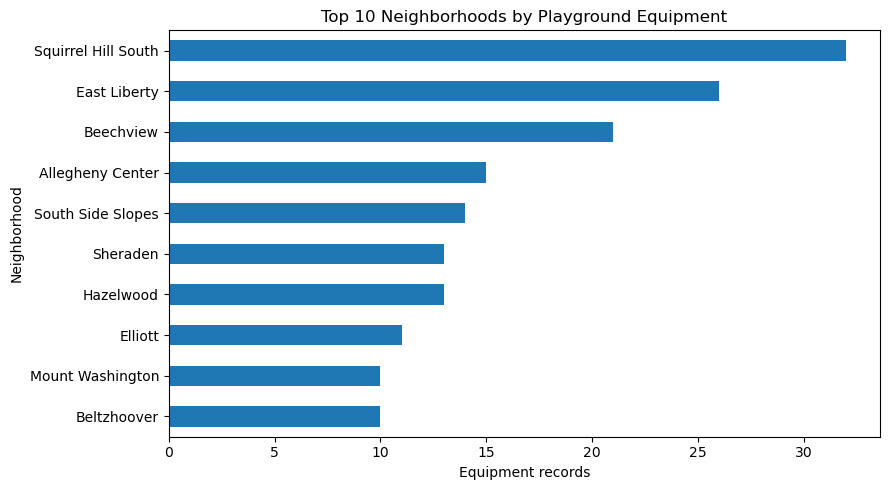

In [5]:
top10 = counts.head(10).sort_values("equipment_count")

ax = top10["equipment_count"].plot(kind="barh", figsize=(9, 5))
ax.set_title("Top 10 Neighborhoods by Playground Equipment")
ax.set_xlabel("Equipment records")
ax.set_ylabel("Neighborhood")
plt.tight_layout()
plt.savefig("playfulness_top10.png", dpi=150, bbox_inches="tight")
plt.show()

## Equipment types

I wanted to see what kinds of equipment appear most often. This isn't part of my main score but it could be useful later.

In [6]:
clean["equipment_type"].dropna().value_counts().head(10)

equipment_type
Play Area 5 to 12        103
Play Area 2 to 5          77
Swing 2 Bays              66
Swing 3 Bays              43
Play Area 2 to 12         25
Whirl                     23
Geo Climber               13
Spinner - Cozy Cocoon     11
Slide                      9
Swing 4 Bays               9
Name: count, dtype: Int64

## What I found

This gives us a starting point for the Playfulness metric. The code below prints the actual counts so we can use them in our group check-in.

In [7]:
first = counts.iloc[0]
first_name = counts.index[0]
top_three = ", ".join(counts.head(3).index.tolist())

summary = (
    "For my Playfulness metric I used WPRDC's Playground Equipment data. "
    f"After removing rows without a neighborhood I had {len(clean)} records "
    f"across {clean['neighborhood'].nunique()} neighborhoods. "
    f"{first_name} had the most equipment records with {int(first['equipment_count'])}. "
    f"The top three were {top_three}. "
    "I used the number of equipment records to compare the neighborhoods. "
    "This is a simple starting point since more equipment does not always mean a better playground."
)
print(summary)
Path("playfulness_checkin_summary.txt").write_text(summary, encoding="utf-8")

For my Playfulness metric I used WPRDC's Playground Equipment data. After removing rows without a neighborhood I had 445 records across 68 neighborhoods. Squirrel Hill South had the most equipment records with 32. The top three were Squirrel Hill South, East Liberty, Beechview. I used the number of equipment records to compare the neighborhoods. This is a simple starting point since more equipment does not always mean a better playground.


442

## Saving the results

I saved the scores as a CSV so my group can combine them with the other two metrics later.

In [8]:
counts.reset_index().to_csv("playfulness_scores_by_neighborhood.csv", index=False)
print("Saved playfulness_scores_by_neighborhood.csv")
print("Saved playfulness_top10.png")
print("Saved playfulness_checkin_summary.txt")

Saved playfulness_scores_by_neighborhood.csv
Saved playfulness_top10.png
Saved playfulness_checkin_summary.txt


## Limitations

This is not a perfect way to measure how fun a neighborhood is. Bigger neighborhoods might have more equipment just because they have more space. The dataset also doesn't tell us the quality of each playground. WPRDC notes that this dataset has not been updated since 2021.

For now I think equipment count is a simple metric we can use for the check-in. We could also look at equipment variety for the final project.

Source: [City of Pittsburgh Playground Equipment — WPRDC](https://data.wprdc.org/dataset/playground-equipment)